# 06 · 量子启发式算法：模拟分叉求解大规模 Max-Cut

对应讲义实验 E · 前置：无（04 的 Max-Cut 部分有助于理解）

**问题**：实验 C 的 Max-Cut 只有 5 个顶点，真实问题动辄上千个变量。G22 是一个 2,000 个顶点的基准图，有 $2^{2000}$ 种分法，枚举毫无可能。

**思路**：模拟分叉（Simulated Bifurcation，SB）受量子绝热演化启发，但本身是经典算法：每个变量是一个振子，随控制参数增大分叉到 ±1，符号就是分组。它能在 CPU、GPU、昇腾 NPU 上大规模并行，今天就能求解实际规模的问题。

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
import time
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import coo_matrix
from mindquantum.algorithm.qaia import BSB, DSB
from mqlab import data_path

## 1. 问题：把 Max-Cut 写成 Ising 模型

给每个顶点一个自旋 $x_i = \pm 1$ 表示分组。一条边两端异组时 $x_ix_j = -1$，所以割边数是

$$\text{cut}(x) = \sum_{(i,j)\in E} \frac{1 - x_ix_j}{2} = \frac{1}{4}\Big(\sum_{i,j} A_{ij} - x^\top A x\Big),$$

其中 A 是对称的邻接矩阵，每条边出现两次。最大化割边数，就是最小化 Ising 能量 $E = -\frac{1}{2}x^\top Jx$，耦合矩阵取 $J = -A$。

In [2]:
def cut_value(A, x):                 # 分组 x（元素为 ±1）的割边数
    return (A.sum() - x @ (A @ x)) / 4

## 2. 直觉：振子分叉

先在一个 12 个顶点、18 条边的小图上看清算法在做什么。弹道模拟分叉（BSB）的每个变量是一个振子，从 0 附近出发；控制参数从 0 增加到 1，振子陆续“分叉”到 +1 或 −1。`solver.p` 是控制参数的取值表，每次只给一个值，就能逐步观察：

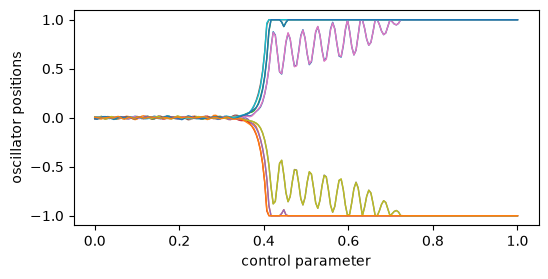

分组： [ 1 -1  1 -1 -1  1  1 -1 -1  1  1 -1] 割边数： 16.0


In [3]:
small = nx.to_numpy_array(nx.random_regular_graph(3, 12, seed=2))
np.random.seed(0)
solver = BSB(-small, n_iter=1)       # 每次 update() 只演化一步
traj = []
for a in np.linspace(0, 1, 200):     # 控制参数从 0 增加到 1
    solver.p = [a]
    solver.update()
    traj.append(solver.x[:, 0].copy())

plt.figure(figsize=(6, 2.8))
plt.plot(np.linspace(0, 1, 200), traj, lw=1)
plt.xlabel('control parameter')
plt.ylabel('oscillator positions')
plt.show()
x = np.sign(solver.x[:, 0])
print('分组：', x.astype(int), '割边数：', cut_value(small, x))

控制参数较小时，所有振子都停在 0 附近；越过分叉点后，耦合把它们推向 ±1，符号就是分组。这个小图的割边数 16，正是暴力枚举 $2^{12}$ 种分法得到的最优值。

## 3. 求解 G22

G22 有 2,000 个顶点、19,990 条边，已知最优割为 13,359。数据文件首行是“顶点数 边数”，之后每行是 `i j w`（顶点编号从 1 开始）。下面是完整的程序（与讲义相同）：

In [4]:
i, j, w = np.loadtxt(data_path('G22.txt'), skiprows=1, unpack=True)
i, j = i.astype(int) - 1, j.astype(int) - 1   # 编号从 0 开始
A = coo_matrix((w, (i, j)), shape=(2000, 2000))
A = (A + A.T).tocsr()                          # 无向图：对称化

np.random.seed(0)                              # 固定随机初值
t0 = time.perf_counter()
solver = DSB(-A, batch_size=100, n_iter=1000)  # J = −A，100 条轨迹并行
solver.update()
cuts = solver.calc_cut()
print(f'best cut = {cuts.max():.0f}，用时 {time.perf_counter() - t0:.1f} s')

best cut = 13356，用时 4.5 s


离散模拟分叉（DSB）达到已知最优值的 99.98%。

### 现场改一改：先预测，再运行

每一处先写下预测，再运行：

1. **随机分组作为基线**：随机给每个顶点分组，割边数大约是？　A 约 5,000　B 约 10,000　C 约 13,000（运行下面的单元格）
2. **迭代更多步**：上面的单元格改成 `solver = DSB(-A, batch_size=100, n_iter=3000)`，再试试 100、300。最好的割边数会怎样？　A 基本不变　B 稳步提高，但越来越慢　C 先升后降
3. **换成弹道模拟分叉**：上面的单元格改成 `solver = BSB(-A, batch_size=100, n_iter=1000)`。与 DSB 的 13,356 相比？　A 更好　B 更快，但略差　C 无法收敛

In [5]:
x = np.random.choice([-1, 1], size=2000)       # 随机分组
print(f'随机分组：cut = {cut_value(A, x):.0f}')

随机分组：cut = 9932


<details><summary>答案</summary>

1. B：约 10,000。G22 有 19,990 条边，随机分组时每条边被割断的概率都是 1/2。
2. B：n_iter = 100、300、1000、3000 时依次为 13,293、13,343、13,356、13,357，越来越接近已知最优 13,359，收益递减，耗时却线性增长。
3. B：BSB 1,000 步得到 13,333，比 DSB 快，但略差；300 步左右就已饱和。
</details>

## 4. 深入：与贪心搜索比较

随机分组太弱。更像样的经典基线是贪心局部搜索：从随机分组出发，反复翻转能让割边数增加最多的顶点，直到无法改进。翻转顶点 i 带来的增量是 $x_i\,(Ax)_i$。

In [6]:
rng = np.random.default_rng(0)
best = 0
for start in range(10):                        # 10 个随机起点，取最好
    x = rng.choice([-1, 1], 2000).astype(float)
    while True:
        gain = x * (A @ x)                     # 翻转每个顶点带来的增量
        k = int(np.argmax(gain))
        if gain[k] <= 0:
            break
        x[k] = -x[k]
    best = max(best, cut_value(A, x))
print(f'贪心局部搜索：{best:.0f}；模拟分叉：{cuts.max():.0f}；已知最优：13359')

贪心局部搜索：12887；模拟分叉：13356；已知最优：13359


模拟分叉明显好于贪心搜索。它是今天就能落地的“量子思想”；也提醒我们：量子算法要证明价值，必须先赢过这样强的经典对手。

## 课后练习（开放）

- 把第 3 节的 `batch_size` 依次改为 1、10、100、1000（1000 在 CPU 上要一两分钟）：并行的轨迹越多，最好的割边数越高吗？耗时怎样变化？
- 有 GPU 或昇腾 NPU 时，设置 `backend='gpu-float32'` 或 `backend='npu-float32'`（分别需要 PyTorch 或 torch_npu），比较速度。

## 小结

- 量子启发式算法在经典硬件上运行，不需要量子计算机，今天就能求解大规模组合优化问题。
- 迭代步数越多，结果越好，耗时也线性增长；BSB 更快，DSB 通常更准。
- 同一套接口只需改 `backend` 参数，就能从 CPU 切换到 GPU 或昇腾 NPU。